# Lecture 2 · From a raw PDF to chunks, vectors, and a graph

How will the system find the borrowing limit in a table on page 1 and the renewal condition in a paragraph on page 2? Follow those two pieces of evidence from the [Library Borrowing Guide](../data/library-guide.pdf) into a searchable index.

| Stage | What to find |
| --- | --- |
| [Set up the pipeline](#step-1) | Which model describes images, which interprets text, and which encodes a passage as numbers |
| [Parse the guide](#step-4) | A typed block holding the renewal condition and the page where it appears |
| [Construct the chunks](#step-5) | Overlapping windows of body text, a table analysis, and an image description |
| [Inspect the index](#step-6) | One chunk's text and vector under the same ID, and a graph edge linked back to its supporting chunk |

**To run the lab**, select the project's Python kernel and start from the project root or `lectures/`. The project README gives the install commands. Configure the text, vision, and embedding models in `lectures/.env` using `lectures/.env.example`. Docling parses the PDF locally and may download its model files the first time. Building a fresh index sends the guide's text and image to the configured model services.

The displayed examples come from earlier runs of the core workflow. Your model, parser version, and existing index can change counts, descriptions, and IDs. Run the cells in order to build or reuse your own copy. Lecture 3 will open the index from disk.

[Previous · Lecture 1, the question and scenario](lecture_1_introduction.ipynb) · [Project setup](../README.md#run-the-project)

<a id="step-1"></a>
## 1. Set up the document, models, and storage

In [1]:
import os
from pathlib import Path
from dotenv import load_dotenv
from lightrag.llm.openai import openai_complete_if_cache, openai_embed
from lightrag.utils import EmbeddingFunc
from raganything import RAGAnything, RAGAnythingConfig, set_prompt_language

# Start the notebook from the project folder or its lectures folder.
project_dir = Path.cwd()
if project_dir.name == "lectures":
    project_dir = project_dir.parent

pdf_path = project_dir / "data/library-guide.pdf"
parsed_dir = project_dir / "outputs/parsed"
storage_dir = project_dir / "outputs/library_rag_storage"

load_dotenv(project_dir / "lectures/.env")
api_key = os.getenv("OPENAI_API_KEY")
base_url = os.getenv("OPENAI_BASE_URL")
llm_model = os.getenv("LLM_MODEL")
vision_model = os.getenv("VISION_MODEL")
embedding_model = os.getenv("EMBEDDING_MODEL")
model_settings = ("LLM_MODEL", "VISION_MODEL", "EMBEDDING_MODEL", "EMBEDDING_DIM")
missing = [name for name in model_settings if not os.getenv(name)]
if missing:
    raise ValueError(f"Set {', '.join(missing)} in lectures/.env (see lectures/.env.example).")
embedding_dim = int(os.environ["EMBEDDING_DIM"])

print(f"""Source: {pdf_path.name}
Parsed files: {parsed_dir}
Index: {storage_dir}
Text model: {llm_model}
Vision model: {vision_model}
Embedding model: {embedding_model} ({embedding_dim} dimensions)""")

Source: library-guide.pdf
Parsed files: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed
Index: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage
Text model: gpt-6-luna
Vision model: gpt-6-luna
Embedding model: text-embedding-3-small (1536 dimensions)


<a id="step-2"></a>
## 2. Assign interpretation, vision, and embedding to their models

**Question for this step: Who interprets content, and who turns text into numbers?** The next cell defines the three model callbacks. Defining them does not send a model request.

```mermaid
flowchart LR
    T["Text, table structure, or an extraction task"] --> L["llm: text model"] --> O["Analysis, entities, relationships, keywords, or an answer"]
    I["Image and related text"] --> V["vision: vision model"] --> D["Text description of the image"]
    S["A batch of texts"] --> E["embed: embedding model"] --> N["One numeric vector per text"]
```

`calls` is the current kernel's **model call log**. Each callback records its input and output so that we can inspect what happened. It is not the persistent cache; resetting this list does not clear cached results on disk.

**Remember these roles:** `llm` interprets and generates text; `vision` interprets images; `embed` encodes text. The text model extracts entities and relationships. Embedding alone does not build a graph or write a summary.

The callbacks use LightRAG’s OpenAI helpers. The plain Python list `calls` retains successful model inputs and outputs for the core examples below. Vision records keep the text and image count; Step 4 displays the image. Embedding records keep the vector shape and first six coordinates. `EmbeddingFunc` in Step 3 declares the model and dimensions, while `openai_embed.func` sends those dimensions to the API.

In [2]:
# Keep model inputs and outputs so we can read them during the core steps.
calls = []

async def llm(prompt, system_prompt=None, history_messages=None, **kwargs):
    output = await openai_complete_if_cache(
        llm_model, prompt, system_prompt=system_prompt,
        history_messages=history_messages, base_url=base_url, api_key=api_key, **kwargs,
    )
    calls.append({
        "kind": "llm", "prompt": prompt, "system_prompt": system_prompt,
        "history_messages": history_messages or [], "output": output,
    })
    return output

async def vision(prompt, system_prompt=None, image_data=None, messages=None, **kwargs):
    # Ingestion supplies a PNG; image-enhanced queries supply complete messages.
    if messages is None:
        messages = []
        if system_prompt:
            messages.append({"role": "system", "content": system_prompt})
        content = [{"type": "text", "text": prompt}]
        if image_data:
            content.append({
                "type": "image_url",
                "image_url": {"url": f"data:image/png;base64,{image_data}"},
            })
        messages.append({"role": "user", "content": content})

    output = await openai_complete_if_cache(
        vision_model, "", messages=messages, base_url=base_url, api_key=api_key, **kwargs,
    )
    image_count = sum(
        part["type"] == "image_url"
        for message in messages if isinstance(message["content"], list)
        for part in message["content"]
    )
    calls.append({
        "kind": "vision", "prompt": prompt, "system_prompt": system_prompt,
        "images": image_count, "output": output,
    })
    return output

async def embed(texts):
    vectors = await openai_embed.func(
        texts, model=embedding_model, base_url=base_url, api_key=api_key,
        embedding_dim=embedding_dim, max_token_size=8192,
    )
    calls.append({
        "kind": "embed", "texts": list(texts),
        "shape": vectors.shape, "sample": vectors[0, :6].tolist(),
    })
    return vectors

<a id="step-3"></a>
## 3. Connect the parser, model callbacks, and indexing engine

**Question for this step: Who connects the parser, models, and indexes?**

| Component | Role in this lesson |
| --- | --- |
| Docling | Recognizes text, a table, and an image in the PDF |
| RAGAnything | Coordinates multimodal processing and sends content through ingestion and querying |
| LightRAG | Splits text, manages vector and graph indexes, retrieves evidence, and coordinates answer generation |

This project uses LightRAG, which follows a graph-assisted retrieval approach. It does not separately invoke Microsoft's GraphRAG package.

**Before running, notice two settings:** `chunk_token_size=75` and `chunk_overlap_token_size=20`. They will determine how the ordinary text becomes overlapping chunks. A token is a unit used by a model's tokenizer; it is not necessarily a whole word or character.

The next cell creates `rag` and selects English prompts. It does not ingest the PDF yet. On your first pass, just confirm the `docling` parser, the three model callbacks, and the 75/20 chunking settings. We will inspect their effect in section 5.

In [3]:
set_prompt_language("en")

config = RAGAnythingConfig(
    parser="docling",
    parser_output_dir=str(parsed_dir),
    working_dir=str(storage_dir),
    display_content_stats=False,
)

rag = RAGAnything(
    config=config,
    llm_model_func=llm,
    vision_model_func=vision,
    embedding_func=EmbeddingFunc(
        embedding_dim=embedding_dim,
        max_token_size=8192,
        model_name=embedding_model,
        func=embed,
    ),
    lightrag_kwargs={
        "llm_model_name": llm_model,
        "chunk_token_size": 75,
        "chunk_overlap_token_size": 20,
        "addon_params": {"language": "English"},
    },
)

INFO: RAGAnything initialized with config:
INFO:   Working directory: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage
INFO:   Parser: docling
INFO:   Parse method: auto
INFO:   Multimodal processing - Image: True, Table: True, Equation: True
INFO:   Max concurrent files: 1


<a id="step-4"></a>
## 4. Parse the PDF into typed blocks and source locations

**Question for this step: What does the program receive for text, a table, and an image?**

```mermaid
flowchart LR
    PDF["Two-page PDF"] --> D["Local Docling parsing"]
    D --> ID["doc_id: document identifier"]
    D --> T["21 text blocks"]
    D --> TB["1 table block"]
    D --> I["1 image block"]
```

**Input → operation → output:** PDF → `parse_document` → `content_list` and `doc_id`.

**Predict before running:** “3 books” and “14 days” should appear in a table block. The renewal condition and “7 extra days” should appear in text on page 2. The next cell parses the material; it does not generate an answer or compute embeddings.

**In the parsing output, find two things:**

1. The type counts: `text: 21, table: 1, image: 1`.
2. The original text describing when a book can be renewed, and its `page_idx`.

The PDF has a text layer, so OCR is disabled. On its first run, Docling may still download local layout or table-recognition models. This example has no equations. In a document containing equations, any `equation` blocks recognized by the parser can enter the later multimodal processing stage.

**Parse the PDF and inspect its contents**

`rag.parse_document` returns the typed blocks and a document ID. The cell counts text, table, and image blocks. It selects the renewal sentence by its wording so you can check its page, then displays the extracted diagram when one is available.

INFO: Starting document parsing: /Users/weiningxu/Documents/Project/rag_anything_playground/data/library-guide.pdf
INFO: Using docling parser with method: auto
INFO: Detected PDF file, using parser for PDF...
/Users/weiningxu/Documents/Project/rag_anything_playground/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1119 11:27:59.928000 67253 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.
Loading weights: 100%|██████████| 770/770 [00:00<00:00, 13630.00it/s]
INFO: Parsing /Users/weiningxu/Documents/Project/rag_anything_playground/data/library-guide.pdf complete! Extracted 23 content blocks



Document ID:
doc-501ac0a4b56d2d98331eb3d9164f0dfd

Parsed blocks by type:
text 21
table 1
image 1

Selected parsed block:
{'type': 'text', 'text': 'If nobody else has reserved it, renew once for 7 extra days.', 'page_idx': 1}

Image metadata:
{'type': 'image', 'img_path': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/parsed/library-guide_39d2f00c/library-guide/docling/images/image_0.png', 'image_caption': ['Figure 1. Renewal steps'], 'image_footnote': [], 'page_idx': 1}


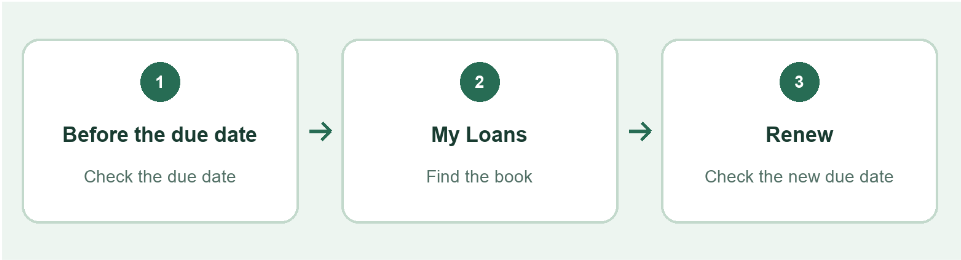

In [4]:
from collections import Counter

content_list, doc_id = await rag.parse_document(str(pdf_path), allow_ocr=False)
block_counts = Counter(block["type"] for block in content_list)
renewal_block = next(
    (block for block in content_list if "7 extra days" in block.get("text", "").lower()),
    None,
)
image_block = next((block for block in content_list if block["type"] == "image"), None)

print(f"""
Document ID:
{doc_id}

Parsed blocks by type:
text {block_counts["text"]}
table {block_counts["table"]}
image {block_counts["image"]}

Selected parsed block:
{renewal_block or "Inspect the text blocks for the renewal condition."}

Image metadata:
{image_block or "No image block was parsed."}""")

from IPython.display import Image, display

if image_block and Path(image_block["img_path"]).is_file():
    display(Image(filename=image_block["img_path"], width=520))

### 4.1 Read the parsed block schema

A parsed text block has this shape. The sentence below illustrates the renewal rule; inspect the output above for the exact parsed wording.

```json
{
  "type": "text",
  "text": "If nobody else has reserved the book, you may renew it once for 7 extra days.",
  "page_idx": 1
}
```

`page_idx=1` means page **2**, because page indices start at zero. A table block stores cell structure in `table_body`; an image block's `img_path` points to an extracted PNG.

The 21 text blocks also include headings, captions, and page numbers. The count does not mean there are 21 complete rules.

### 4.2 Q&A — Parsed blocks are not retrieval chunks

**Pause and predict — Check 1: Do we already have 23 chunks and 23 vectors?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

**Not yet.** We have 23 parsed blocks representing the PDF's content and layout. Ingestion will join and split the ordinary text, then process the table and image. This run ultimately produces 6 chunks.

If you answered “yes,” you are mixing up **parsed layout elements** and **retrieval units**. Follow the same evidence from section 4 into section 5.

</details>

<a id="step-5"></a>
## 5. Route the blocks and construct retrieval chunks

**Question for this step: How does parsed content become material we can search later?** `insert_content_list` looks like one call, but it coordinates all of the work below.

```mermaid
flowchart TD
    INPUT["23 parsed blocks"] --> T["21 text blocks"]
    INPUT --> TABLE["1 table"]
    INPUT --> IMAGE["1 image"]
    T --> JOIN["Join ordinary text: 180 tokens"]
    JOIN --> SPLIT["Window: 75 tokens; overlap: 20 tokens"]
    SPLIT --> FOUR["4 text chunks"]
    TABLE --> LLM["Text model analyzes table structure and nearby text"]
    LLM --> TC["Table chunk: 1941 tokens"]
    IMAGE --> VLM["Vision model describes the image"]
    VLM --> IC["Image chunk: 430 tokens"]
    FOUR --> STORE["Store 6 chunks and their provenance"]
    TC --> STORE
    IC --> STORE
```

The three branches produce textual retrieval units. Analysis and embedding are separate tasks; section 5.2 follows the multimodal branch.

### 5.1 Join and split ordinary text

**Understand the text windows.** The joined ordinary text contains 180 tokens in this run. A 75-token window with a 20-token overlap advances by 55 tokens each time.

| Text chunk | Token range | Length | Overlap with previous chunk |
| --- | --- | ---: | --- |
| 1 | 1–75 | 75 | None |
| 2 | 56–130 | 75 | 56–75 |
| 3 | 111–180 | 70 | 111–130 |
| 4 | 166–180 | 15 | 166–180 |

The final chunk has only 15 tokens and is entirely contained in the end of chunk 3. This last pair therefore shares 15 tokens; 20 is the configured overlap for full windows.

Overlap repeats text near a boundary in adjacent chunks, reducing the chance that a split loses important context. Compare the end of one text chunk with the beginning of the next. Token windows do not guarantee complete sentences, and a chunk can cross a page boundary.

**After running, check the status only:** `fully_processed` should be `True`; this saved run has `chunks_count=6`. A successful `insert_content_list` call returns `None`. The subsequent `status` record tells us whether processing finished.

### 5.2 Interpret the table and image with surrounding text

**Question:** How can a table or image become searchable text without losing its structure?

**Analysis:** Interpretation receives the original modality plus selected context. Graph extraction later receives the resulting textual representation.

| Material | What the earlier analysis receives | What graph extraction later receives |
| --- | --- | --- |
| Body text | No separate table/image analysis | One text chunk |
| Table | Structured table cells, captions or footnotes if present, and surrounding text | Table structure and metadata, plus the generated analysis |
| Image | Actual image pixels, caption if present, and surrounding text | A textual representation containing the visual description, image path, caption, and contextual information |

**Select nearby context before interpretation.** The default context setting includes text from the current page and one page on either side, subject to a 2,000-token limit. Our guide has only two short pages, so text from both pages can be included. The default context filter includes text, not the nearby table or image pixels themselves.

For example, the cells contain **3 books** and **14 days**; renewal information in the table analysis can come from nearby paragraphs. Inspect the original PDF before attributing that rule to the table itself. The text model interprets the table; the vision model interprets image pixels. Their descriptions become inputs to chunk storage, embedding, and graph extraction.

**Index the parsed material and read its status**

`rag.insert_content_list` builds or reuses the index. This cell then looks up the guide's processing status and chunk IDs, which we will use to inspect the saved records. The interval in `calls` identifies work performed during this insertion.

In [5]:
if not api_key:
    raise ValueError(
        "Set OPENAI_API_KEY in lectures/.env for the configured model service, "
        "then restart the kernel and run the cells again to build the index."
    )

before_insert = len(calls)
await rag.insert_content_list(content_list, file_path=str(pdf_path), doc_id=doc_id)
after_insert = len(calls)

status = await rag.get_document_processing_status(doc_id)
print(f"""Fully processed: {status["fully_processed"]}
Stored chunk count: {status["chunks_count"]}
Full status record: {status}""")

if not status["fully_processed"] or not status.get("chunks_list"):
    raise RuntimeError(
        "The guide is not fully indexed. Inspect the status above and the ingestion "
        "log before continuing to the chunk and graph inspection."
    )

INFO: Parser 'docling' installation verified
INFO: Initializing LightRAG with parameters: {'working_dir': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage', 'llm_model_name': 'gpt-6-luna', 'chunk_token_size': 75, 'chunk_overlap_token_size': 20, 'addon_params': {'language': 'English'}}
INFO: [] Loaded graph from /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/graph_chunk_entity_relation.graphml with 33 nodes, 75 edges
INFO:nano-vectordb:Load (33, 1536) data
INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/vdb_entities.json'} 33 data
INFO:nano-vectordb:Load (75, 1536) data
INFO:nano-vectordb:Init {'embedding_dim': 1536, 'metric': 'cosine', 'storage_file': '/Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage/vdb_relationships.json'} 75 data
INFO:nano-vector

Fully processed: True
Stored chunk count: 6
Full status record: {'exists': True, 'text_processed': True, 'multimodal_processed': True, 'fully_processed': True, 'chunks_count': 6, 'chunks_list': ['chunk-9afabfd0277eadab270f8c9f0d4f67b9', 'chunk-f74d3981177947bc583a0860d03ffe3f', 'chunk-b5b66dc4cdc65aee472efcef7cbf0db9', 'chunk-0bec09cbf50b78e30405fdc3229058fb', 'chunk-73e03336d64bd8478972d0d7b5bf162b', 'chunk-72b56bc685fea8dbd9e08a18a4a7c1b1'], 'status': <DocStatus.PROCESSED: 'processed'>, 'updated_at': '2026-11-19T03:28:01+00:00', 'raw_status': {'status': <DocStatus.PROCESSED: 'processed'>, 'chunks_count': 6, 'chunks_list': ['chunk-9afabfd0277eadab270f8c9f0d4f67b9', 'chunk-f74d3981177947bc583a0860d03ffe3f', 'chunk-b5b66dc4cdc65aee472efcef7cbf0db9', 'chunk-0bec09cbf50b78e30405fdc3229058fb', 'chunk-73e03336d64bd8478972d0d7b5bf162b', 'chunk-72b56bc685fea8dbd9e08a18a4a7c1b1'], 'content_summary': 'Library Borrowing Guide\n\nBorrowing and returning books\n\nBefore borrowing, check that your 

### 5.3 Inspect interpretation and encoding as separate operations

The following cells each inspect one complete model operation: table analysis, vision analysis, or embedding. Each groups its input and output together. **Compare these two kinds of result:**

- An image or table description is readable text, such as an explanation of the renewal diagram.
- An embedding result has an array shape and a numeric sample. For example, `(N, 1536)` means N vectors, each with 1536 dimensions.

In this example, the table chunk explains the 3-book limit and 14-day loan period. The image chunk describes the renewal steps. Descriptions may incorporate nearby text, so return to the PDF when checking a fact.

If this run reused an already processed document or cached results, there may be fewer new calls, or no sample for a particular task. An empty `calls` list alone does not show that ingestion failed; also inspect the completion status.

**Select the ingestion model calls and count them**

Select table, vision, and embedding samples from this ingestion, then print the number of each kind of call. Reusing an index or cached results can leave a sample as `None`.

In [6]:
from raganything.prompt import PROMPTS

index_calls = calls[before_insert:after_insert]
table_sample = next((call for call in index_calls if call.get("system_prompt") == PROMPTS["TABLE_ANALYSIS_SYSTEM"]), None)
vision_sample = next((call for call in index_calls if call["kind"] == "vision"), None)
embedding_sample = next((call for call in index_calls if call["kind"] == "embed"), None)

call_counts = Counter(call["kind"] for call in index_calls)
print(f"""llm {call_counts["llm"]}
vision {call_counts["vision"]}
embed {call_counts["embed"]}""")

llm 0
vision 0
embed 0


**Inspect one table-analysis call**

Read the instructions, input, and response together from `table_sample`, recorded by the `llm` callback.

In [7]:
if table_sample:
    table_instructions = table_sample.get("system_prompt", "No response recorded.")
    table_input = table_sample.get("prompt", "No response recorded.")
    table_response = table_sample.get("output", "No response recorded.")
else:
    table_instructions = table_input = table_response = "No new table-analysis call was recorded."

print(f"""
Table instructions:
{table_instructions}

Table input:
{table_input}

Table response:
{table_response}""")


Table instructions:
No new table-analysis call was recorded.

Table input:
No new table-analysis call was recorded.

Table response:
No new table-analysis call was recorded.


**Inspect one vision-analysis call**

Read the instructions, input text, image count, and response together from `vision_sample`. Step 4 shows the actual image; encoded image bytes are not printed.

In [8]:
if vision_sample:
    vision_response = vision_sample.get("output", "No response recorded.")
    print(f"""Instructions: {vision_sample["system_prompt"]}
Input: {vision_sample["prompt"]}
Images: {vision_sample["images"]}

Vision response:
{vision_response}""")
else:
    print("No new vision call was recorded.")

No new vision call was recorded.


**Inspect one embedding call**

Read the first input text alongside the array shape and six coordinates of its vector. The row count gives the number of texts in that request. The column count gives the embedding dimension.

In [9]:
if embedding_sample:
    print(f"""
Selected embedding input:
{embedding_sample["texts"][0]}
Vector shape: {embedding_sample["shape"]}
First six coordinates: {embedding_sample["sample"]}""")
else:
    print("No new embedding call was recorded.")

No new embedding call was recorded.


### 5.4 Q&A — Windows, descriptions, and model roles

**Pause and predict — Check 2: Does the second text chunk start at token 56 or 76? Why can the table chunk exceed 75 tokens?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

It starts at **56**, because the stride is `75 - 20 = 55`. The 75-token window applies to ordinary text. Tables and images use separate processing paths, so their chunks may be longer.

If you chose 76, revisit overlap. If you expected the table chunk to stay below 75 tokens, trace the three content branches in the diagram.

</details>

**Pause and predict — Check 3: Who extracts entities and relationships from “renewal adds 7 days,” and who turns text into numbers?**

Answer in your own words before opening the explanation.

<details>
<summary>Show the answer and diagnose the misunderstanding</summary>

The text model extracts entities and relationships. The embedding model encodes the supplied text as vectors. The vision model interprets images.

If you thought one embedding call did everything, return to section 2 and separate **interpretation and generation by an LLM/VLM** from **encoding by an embedding model**.

</details>

<details>
<summary>What changes for an equation or another content type?</summary>

The source PDF has no equations, so the saved run does not demonstrate this branch. An equation processor can combine formula text (including LaTeX), its description, and nearby context; a text-model call produces an explanation and a main entity. That textual representation then enters the same chunk, vector, extraction, and graph-merge stages. A generic processor handles other routed content types. These are additional modality branches, not an extra required stage after every image or table. See the [installed processors](../.venv/lib/python3.14/site-packages/raganything/modalprocessors.py).

</details>

<a id="step-6"></a>
## 6. Build and inspect the chunk store, vector indexes, and graph

**The ingestion call in Step 5 has already performed these indexing operations.** This section explains those operations in dependency order and reads their saved results. It does not ingest the document a second time or ask an answer question.

We will follow one sentence from the PDF:

> If nobody else has reserved it, renew once for 7 extra days.

Here, **renew** means asking to keep the book longer. The sentence gives both a condition and a time limit. We want the system to keep that information so it can answer a question later.

### 6.1 Keep readable chunks and encode them as vectors

A **chunk** is a saved piece of text. Our sentence is part of a chunk. Making a vector does not remove the text.

Each chunk also has an **ID**. An ID is a label used to find that particular chunk. The label itself is not a summary of the text.

Here is a simplified view of one real saved chunk. The ID and text are shortened for reading:

```text
ID:   chunk-f74d3981…
Text: … Open My Loans, find the book, and click "Renew".
      If nobody else has reserved it, renew once for 7 extra days. …
```

**Next, encode text for similarity search.**

The embedding model takes the chunk's text and produces numbers. That list is its **vector**, also called an **embedding**.

Later, the system can use these numbers to find text related to a question. For example, “Can I keep the book longer?” may match the renewal text, even though the words differ. This is an illustration, not an extra query run by this cell.

```mermaid
flowchart TD
    ID["A chunk ID links two saved records"] --> T["Text: words a person or answer model can read"]
    ID --> V["Vector: numbers used to find related content"]
```

**Focus on what the numbers are for. You do not need to read meaning from each number.** The answering model will later read the selected text, not the vector's numbers.

**How to read the next output**

The cell below selects a chunk containing the renewal condition, then reads its text and vector by ID. You can assign a different `chunk_index` to inspect another saved record.

| If you see this | Read it as |
| --- | --- |
| The selected chunk ID | The label for this saved piece of text |
| A paragraph under that label | The text is still available to read |
| `Dimensions: 1536` | This vector contains 1536 numbers |
| `First six coordinates: [...]` | Only the first six numbers are shown |

**Your task:** Find the sentence about “7 extra days.” Then find the vector record with the same chunk ID. Seeing the same ID is enough; leave the individual numbers aside.

<details>
<summary>Optional: where is this chunk in the PDF?</summary>

This saved chunk spans pages 1–2. Its fields are `page_idx=0` and `page_idx_end=1`, because page indices start at zero. The renewal sentence itself is on PDF page 2. [Lecture 3](lecture_3_retrieval_and_answering.ipynb#source-trace) follows these source details during retrieval.

</details>

<details>
<summary>Optional: why can stored numbers differ slightly from the original numbers?</summary>

The vector store compresses numbers using a format called float16. Small rounding differences are expected. You only need to check the chunk ID and the vector length here.

</details>

**Read one stored chunk and its vector**

`text_chunks.get_by_ids` loads records in the supplied ID order. Locate the first record containing “7 extra days,” then use its ID with `chunks_vdb.get_vectors_by_ids`. If the wording differs, the first available record is shown. Reading a stored vector makes no model call.

In [10]:
chunk_ids = status["chunks_list"]
chunks = await rag.lightrag.text_chunks.get_by_ids(chunk_ids)

available_indices = [i for i, chunk in enumerate(chunks) if chunk]
if not available_indices:
    raise RuntimeError("No stored records matched the document's chunk IDs.")
chunk_index = next(
    (i for i in available_indices if "7 extra days" in chunks[i]["content"].lower()),
    available_indices[0],
)
selected_chunk_id = chunk_ids[chunk_index]
selected_chunk = chunks[chunk_index]

metadata_lines = [f"{key} {value}" for key, value in selected_chunk.items() if key != "content"]
chunk_metadata = "\n".join(metadata_lines)

print(f"""
Chunk ID:
{selected_chunk_id}

Chunk metadata:
{chunk_metadata}

Chunk text:
{selected_chunk["content"]}""")

vectors_by_id = await rag.lightrag.chunks_vdb.get_vectors_by_ids([selected_chunk_id])
selected_vector = vectors_by_id.get(selected_chunk_id)

if selected_vector is None:
    raise RuntimeError(f"The chunk vector is missing for {selected_chunk_id}.")
print(f"""
Stored vector:
Dimensions: {len(selected_vector)}
First six coordinates: {selected_vector[:6]}""")


Chunk ID:
chunk-f74d3981177947bc583a0860d03ffe3f

Chunk metadata:
tokens 75
chunk_order_index 1
full_doc_id doc-501ac0a4b56d2d98331eb3d9164f0dfd
file_path library-guide.pdf
llm_cache_list ['default:extract:9738f06dd6575e508a8646784deab196', 'default:extract:f83b636ce1938a7302f0f27779fc6dc7']
create_time 1795057421
update_time 1795057472
_id chunk-f74d3981177947bc583a0860d03ffe3f
page_idx 0
page_idx_end 1

Chunk text:
check each title separately.

Return each book on or before its due date.

Library Borrowing Guide

1 / 2

How to Renew

If you need more time, request a renewal before the due date.

Open My Loans, find the book, and click "Renew".

If nobody else has reserved it, renew once for 7 extra days.

If it is reserved

Stored vector:
Dimensions: 1536
First six coordinates: [-0.03424072265625, 0.053375244140625, 0.0274200439453125, -0.0303802490234375, -0.008056640625, -0.0204620361328125]


### 6.2 Extract entities and relationships from each chunk

Now look at the third kind of saved information: the **knowledge graph**.

The text model can identify things mentioned in a passage and describe how they are connected. For example:

```mermaid
flowchart LR
    R["Renewal"] ---|"extends the loan by"| D["7 days"]
```

This is a simplified example, not a complete rule. The original sentence also says that nobody else may have reserved the book.

- An **entity** is a thing or concept, such as renewal or a loan period. It is a **node** in the graph.
- A **relationship** describes a connection between entities. It is an **edge** in the graph.
- A **graph** is a collection of these nodes and connections.

The graph saves `source_id` too. This field contains the label of the chunk that supports a fact. It lets us go back and read the full rule, including its conditions.

```text
A connection about renewal
→ source_id
→ the supporting chunk
→ read the original conditions
```

The connections show meaning. They do not automatically show the order of paragraphs and pictures in the PDF.

#### Connect body text and multimodal representations to the same extraction stage

```mermaid
flowchart TD
    T["Body text"] --> TC["Text chunks"]
    TB["Table cells + surrounding text"] --> TA["LLM table analysis"]
    TA --> TBC["Table structure + analysis"]
    I["Image pixels + surrounding text"] --> IA["Vision-model analysis"]
    IA --> IC["Image description + context"]
    TC --> E["Extract nodes and edges; One chunk per extraction request"]
    TBC --> E
    IC --> E
    E --> G["Merge matching entities and relationships; Save graph and source links"]
```

In this installed version, **all six chunks are processed, but they are not all sent together in one extraction request**. Each request includes one chunk plus the extraction instructions and examples. The image pixels go to the earlier vision-analysis call; the later graph-extraction call receives text.

The framework also creates a node for each table or image and adds connections named **`belongs_to`**. Read that as: “This entity was extracted while processing this table or image.” It is an association with the processed object, not proof that every fact was literally printed inside that object.

The graph represents semantic connections and object associations; it is not automatically a reading-order chain such as `text 1 → image 1 → text 2`.

#### What does the extraction prompt ask?

```text
You are a Knowledge Graph Specialist responsible for extracting entities and relationships from the input text.
Identify clearly defined and meaningful entities in the input text.
Identify direct, clearly stated, and meaningful relationships between previously extracted entities.
```

In the renewal passage, the model identifies **My Loans** and **Book** as two nodes. It connects them because the guide says a borrower can find the book in My Loans. That single call found six nodes and seven relationships in the chunk.

A review pass checks for entities or relationships the first pass missed or formatted incorrectly.


### 6.3 Merge independently extracted nodes and edges

**The model does not need to see every chunk together. Python combines the extraction results by matching entity names.** The chunks keep their own IDs and text; their facts can share nodes in one graph.

Here is what happens with real records from our saved run:

| Extraction result | Entity name | Relationship endpoints |
| --- | --- | --- |
| Text chunk, first pass | `Book`, `Renewal` | `Book` and `Renewal` |
| Table chunk, extraction plus review | `Book`, `Renewal` | `Book` and `Renewal` |

The table's Book–Renewal relationship appears in its **review pass**, rather than its first response. Its renewal information can come from the surrounding text included during analysis.

```mermaid
flowchart TD
    A["Text-chunk result; Book, Renewal, and their relationship"] --> M["Python merge; Match entity names and endpoint pairs"]
    B["Table-chunk extraction + review; Book, Renewal, and their relationship"] --> M
    M --> BOOK["One shared Book node"]
    M --> RENEWAL["One shared Renewal node"]
    BOOK ---|"One combined relationship"| RENEWAL
    M --> E["Keep supporting chunk IDs; Text evidence + table-analysis evidence"]
```

The merge works like this:

1. **Match nodes by name.** After basic text cleanup, `Book` matches an existing `Book` node. Add the new description and source information to that node.
2. **Match edges by their two endpoints.** In this workflow, `Book — Renewal` and `Renewal — Book` identify the same pair. Combine the relationship information instead of creating another copy of the pair.
3. **Keep evidence links.** The combined node or edge records the supporting chunk IDs in `source_id`. This lets retrieval return to the separate chunks later.

An edge with a new endpoint can extend the same graph. For example, a `Book — Due Date` relationship and a `Book — Renewal` relationship share **Book** even though they describe different facts. The chunks themselves do not need a direct `chunk A → chunk B` edge.

**The saved Book–Renewal edge has four supporting chunks:** two body-text chunks, the table-analysis chunk, and the image-analysis chunk.

<details>
<summary>Show the actual source IDs and the two extracted descriptions</summary>

Text-chunk first-pass relationship description:

```text
A book can be renewed once for seven extra days if nobody else has reserved it.
```

Table-chunk review relationship description:

```text
A borrowed book may be renewed once for seven extra days if the stated conditions are met.
```

The final edge's `source_id` includes these IDs; the list below adds labels for readability:

```text
Body text:      chunk-b5b66dc4cdc65aee472efcef7cbf0db9
Body text:      chunk-f74d3981177947bc583a0860d03ffe3f
Table analysis: chunk-cf352990e5eade4fe4af96431997ef38
Image analysis: chunk-816ab159240b772497183b1cde78b387
```

The saved field joins IDs with `<SEP>`. The graph also keeps merged descriptions. Long descriptions can trigger an additional summarization call, but matching these entity names does not require sending every original chunk to one model call.

</details>

**A limitation to remember:** this merge is based on matching names, not automatic understanding of every synonym. If one extraction says `Book` and another says `Volume`, they are not guaranteed to become the same node. The prompt asks for consistent naming, but the model can still use different names. Conversely, identical names can be ambiguous. Vector similarity is not the rule used to merge these nodes.

### 6.4 Preserve evidence separately for every node and edge

Follow two independent extractions. This is a small teaching example, not a literal copy of the saved graph. `chunk-1` and `chunk-2` are short labels that make the links easier to follow.

| Independent extraction | Result |
| --- | --- |
| Chunk 1 discusses renewal | `Book — Renewal` |
| Chunk 2 discusses borrowing rules | `Book — Borrow Rule` |

```mermaid
flowchart LR
    BR["Borrow Rule"] ---|"Supported by chunk 2"| B["Book"]
    B ---|"Supported by chunk 1"| R["Renewal"]
```

Python attaches the producing chunk’s ID to each extraction record and retains supporting IDs during merging. `source_id` answers which chunks supplied this record’s evidence.

There is not just one source label for the entire graph. **Each node and each edge has its own evidence links:**

| Saved graph item | Its own `source_id` points to | Why? |
| --- | --- | --- |
| **Book** node | Chunk 1 and chunk 2 | Both extractions identify Book |
| **Renewal** node | Chunk 1 | This extraction identifies Renewal |
| **Borrow Rule** node | Chunk 2 | This extraction identifies Borrow Rule |
| **Book — Renewal** edge | Chunk 1 | This chunk supports the renewal relationship |
| **Book — Borrow Rule** edge | Chunk 2 | This chunk supports the borrowing-rule relationship |

**Sharing a node does not make every source support every connected edge.** Book has evidence from both chunks, but the Book–Renewal edge in this example still points only to chunk 1.

<details>
<summary>Show what the source_id field can look like</summary>

Using our short teaching IDs:

```text
Book node:                 source_id = "chunk-1<SEP>chunk-2"
Renewal node:              source_id = "chunk-1"
Borrow Rule node:          source_id = "chunk-2"
Book — Renewal edge:       source_id = "chunk-1"
Book — Borrow Rule edge:   source_id = "chunk-2"
```

The actual saved IDs are longer, for example `chunk-f74d3981177947bc583a0860d03ffe3f`. `<SEP>` separates multiple IDs stored in the field. A source ID is a lookup label; it does not contain the original sentence itself.

</details>

During retrieval, follow an edge’s `source_id` to its saved chunk, read the full rule, and use its document/page information to verify the PDF. The combined trace diagram in [Lecture 3](lecture_3_retrieval_and_answering.ipynb#source-trace) connects these graph links with answer citations.

That full sentence matters: the short graph label **Renewal** does not explain the reservation condition. Source links let us retrieve and check it. For table/image-analysis chunks, this lookup returns the saved analysis representation; its provenance helps us check the underlying document. Analysis can include surrounding text, as section 5.2 explains.

The graph contains the facts successfully extracted; it is not guaranteed to capture every fact in every chunk.

### 6.5 Index chunks, entities, and relationships with text embeddings

You can come back to this after the basic three jobs above make sense.

<details>
<summary>Explain chunk vectors, entity vectors, and relationship vectors</summary>

All three are lists of numbers made from text. What changes is the text being encoded.

| Vector type | Text sent to the embedding model | What it helps find |
| --- | --- | --- |
| Chunk vector | A passage containing the renewal rule | A relevant passage |
| Entity vector | An entity's name and description, such as “renewal” and what it means | A relevant thing or concept |
| Relationship vector | The names of two entities and a description of their connection | A relevant connection or rule |

These are simple examples. Ordinary relationship inputs also include keywords; some image or table entities use a short description directly. Section 6.6 shows a graph preview, not all the entity and relationship vectors.

The same embedding model can make all three types. A relationship vector is made from the relationship's description; it is not calculated by subtracting two entity vectors.

Our six chunks have six chunk vectors. The entity and relationship vectors are additional records. One chunk can mention several entities, and the same entity can appear in several chunks.

**Try classifying these:** a full renewal passage; a description of “renewal”; a description of how renewal changes the loan period.

They produce a chunk vector, an entity vector, and a relationship vector, respectively. The difference is the information being encoded, not three different models.

</details>

### 6.6 Read the saved graph

**For the next code cell, do just one thing:** expand the output, find a `source_id`, and look for that chunk ID in the earlier chunk output. This connects the graph back to readable text.

<details>
<summary>Optional: what do the graph preview numbers mean?</summary>

`nodes` are the entities shown; `edges` are their connections. This preview asks for at most 30 nodes. `is_truncated=True` means some of the full graph has been left out of the preview. It is not an error.

</details>

**Read and inspect the graph**

`get_knowledge_graph` loads a preview with at most 30 nodes. The cell prints its size, whether it is truncated, one node, and one edge. Change `node_index` or `edge_index` to inspect another record, and follow its `source_id` back to the chunks.

In [11]:
graph = await rag.lightrag.get_knowledge_graph("*", max_nodes=30)
graph_data = graph.model_dump()

node_index = 0
edge_index = 0
selected_node = graph_data["nodes"][node_index] if graph_data["nodes"] else "No graph nodes."
selected_edge = graph_data["edges"][edge_index] if graph_data["edges"] else "No graph edges."

print(f"""Nodes: {len(graph.nodes)}
Edges: {len(graph.edges)}
Preview truncated: {graph.is_truncated}

Selected graph node:
{selected_node}

Selected graph edge:
{selected_edge}""")

INFO: [] Graph truncated: 33 nodes found, limited to 30
INFO: [] Subgraph query successful | Node count: 30 | Edge count: 72


Nodes: 30
Edges: 72
Preview truncated: True

Selected graph node:
{'id': 'Library Borrowing Guide', 'labels': ['Library Borrowing Guide'], 'properties': {'entity_id': 'Library Borrowing Guide', 'entity_type': 'content', 'description': 'Library Borrowing Guide is the title of the displayed content.<SEP>The Library Borrowing Guide provides instructions for borrowing and returning books.<SEP>The Library Borrowing Guide provides instructions for renewing and returning a book.<SEP>The Library Borrowing Guide provides instructions to check titles separately, return books by their due dates, and request renewals.<SEP>The Library Borrowing Guide explains how to renew a borrowed book, including renewal eligibility, the additional loan period, and the return deadline.<SEP>The Library Borrowing Guide presents student borrowing limits and instructions for checking eligibility, tracking due dates, renewing, and returning books.', 'source_id': 'chunk-b5b66dc4cdc65aee472efcef7cbf0db9<SEP>chunk-f74d39

### 6.7 Q&A — Graph value, evidence, cost, and multiple files

**Check 4: When writing the final answer, should the answer model read the selected text or the vector numbers?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

It reads the **selected text**. The vector helps find that text.

If you chose the numbers, return to the two boxes above. They have different jobs: one helps search; the other supplies readable information.

</details>

**Check 5: A graph connection says that renewal adds seven days. Which field helps you find the text supporting that connection?**

Try an answer before opening the explanation.

<details>
<summary>Show the explanation</summary>

Use **`source_id`**. It points to one or more supporting chunks.

Read the chunk to check the full rule. A short graph description may not show every condition. If you chose the vector's numbers, remember that numbers help with matching; source IDs help find the supporting text.

</details>

**Try it:** chunk A returns `Book — Due Date`; chunk B returns `Book — Renewal`. How many distinct entity names are there, and which name connects the facts?

<details>
<summary>Show the explanation</summary>

There are three: **Book**, **Due Date**, and **Renewal**. **Book** is shared. The two edges meet at that node. Each edge can still point back to its own supporting chunk.

This is a small teaching example, not a claim that the whole saved graph contains only three nodes.

</details>

**Try it:** Book has `source_id` links to chunks 1 and 2. Does that mean chunk 2 must contain the renewal rule?

<details>
<summary>Show the explanation</summary>

No. Book is mentioned in both chunks, but each relationship has its own source links. To check renewal, follow the **Book–Renewal edge's `source_id`**. In this example, that leads to chunk 1.

</details>

#### Why keep a graph as well as vectors?

**A graph is an extra way to find related information. It is not required for every RAG application.** For this two-page guide, ordinary text retrieval, or giving the whole guide to a model, could be enough. We use a graph here to learn how this system works.

| Search method | A plain-English question it helps answer |
| --- | --- |
| Vector search | Which passages have a similar meaning to my question? |
| Graph search | Which things and facts are connected to the subjects in my question? |

For example, our saved graph contains these connections. The edge labels below are shortened for readability:

```mermaid
flowchart LR
    M["My Loans"] ---|"Where borrowers find their books"| B["Book"]
    B ---|"Can be renewed once for 7 extra days; if nobody has reserved it"| R["Renewal"]
```

Imagine that one passage explains where to find a book, while another explains when it can be renewed. The shared **Book** node helps connect those facts. Later, retrieval can use the connections to collect related evidence.

The graph does not replace the source text. A short relationship description may leave out a condition. The answer still needs supporting passages, such as the rule about another person's reservation.

**Keep these jobs separate:** the LLM writes descriptions and extracts facts; Python code saves and merges graph records; the embedding model turns text into numbers for searching. Embedding does not invent the graph's connections.

#### How much extraction work does this small example require?

**It adds substantial work for this tiny document.** A graph can be useful, but it is not automatically the cheapest or best choice for every task. Here, the extra machinery helps us learn.

One earlier English run produced the following sizes. Its generated records can differ from the examples displayed above.

| Stored material | Count | Content tokens, before extraction instructions |
| --- | --- | --- |
| Body-text chunks | 4 | 235 total, including overlap |
| Table-analysis chunk | 1 | 1,941 |
| Image-analysis chunk | 1 | 430 |

The original joined body text has 180 tokens. Its overlapping chunks repeat some text, so their total is larger. The table representation is surprisingly long because it includes cell structures, coordinates, repeated cell data, and generated analysis. These counts describe stored chunk content, not the total API request or a bill.

The six chunks went through **6 initial extraction calls + 6 review calls**. There were also separate table and image analysis calls, embedding work, and later question-answering work. Even the short 15-token text chunk received extraction instructions and worked examples; review calls also included the earlier conversation.

However, **the number of graph edges is not the number of model calls**:

- One extraction response can contain many nodes and edges, as we saw in section 6.2.
- Python merges matching names and saves records locally.
- The full graph in that earlier run had **28 nodes and 67 edges**. **23 edges** are `belongs_to` associations added automatically, without a separate model call for each one.

<details>
<summary>Optional: a rough token estimate for the saved extraction requests</summary>

Counting the stored extraction request strings with the local `cl100k_base` tokenizer gives approximately **48,500 input tokens and 4,400 output tokens** across the 12 extraction responses.

This is a text-based estimate, **not measured billable usage**. The saved strings include serialized history; provider tokenization, message framing, and cached-input pricing can differ. The count excludes table/image interpretation, embeddings, and answering. The callbacks did not record the actual provider token-usage totals for this run.

The lesson is that repeated instructions, examples, and review history can dominate the size of a small source document.

</details>

Possible ways to reduce ingestion cost include using larger text chunks, reducing review passes, or passing a more compact table representation. Each changes what the model sees or checks, so it needs evaluation. None of those settings is changed by this explanation. Choosing a simpler retrieval mode later does not undo graph-building work already done during ingestion.

**Quick check: Does a response containing 6 nodes and 7 edges require 13 extraction requests?**

<details>
<summary>Show the explanation</summary>

No. Our real example returned all 13 records in **one response to one extraction request**. A separate review request can add or correct records afterward. Saving a graph edge and making a model request are different operations.

</details>

#### How do rules in separate PDFs enter one shared index?

**Both PDFs can contribute facts to one shared graph.** Use the same `rag` instance and index for both files. In this notebook, that means the same `working_dir` and LightRAG workspace. Separate indexes do not automatically search or merge with each other.

Imagine splitting our guide into two files. This is a teaching example; the saved run still uses the original single PDF.

| File | Example content | Short name for its supporting chunk |
| --- | --- | --- |
| `file1.pdf` | Students can borrow up to 3 books for 14 days. | A |
| `file2.pdf` | Before the due date, renew a book once for 7 extra days if nobody else has reserved it. | B |

Each file goes through parsing and ingestion. The extraction model reads each chunk and proposes entities and relationships. Suppose the results include:

```text
From chunk A:  Book — Borrowing Rule
From chunk B:  Book — Renewal Rule
```

The name-based merge from section 6.3 also applies across files: the second extraction attaches its renewal relationship to the existing **Book** node.

```mermaid
flowchart LR
    BORROW["Borrowing Rule; 3 books; 14 days"] ---|"Evidence: A in file1.pdf"| BOOK["Book; Shared node"]
    BOOK ---|"Evidence: B in file2.pdf"| RENEW["Renewal Rule; Once; 7 extra days; conditions apply"]
```

The boxes and labels illustrate a possible extraction, not guaranteed model output. The details of a rule can live in node or edge descriptions; every number does not have to become its own node.

| Graph record | Supporting chunks in this example |
| --- | --- |
| Book node | A and B, because both mention Book |
| Book–Borrowing Rule edge | A only |
| Book–Renewal Rule edge | B only |

**The shared Book node connects the facts; each edge's `source_id` still identifies its own evidence.** A chunk lookup leads back to the text and its source file. If both files also produce the same edge endpoints, their relationship information is merged into that edge.

There is no requirement to create a `file1.pdf → file2.pdf` edge or send both complete PDFs to one extraction request. The connection above comes from matching the extracted name **Book**. It does not automatically create a new fact such as a maximum total loan duration; an answer may derive that later if the retrieved rules support it.

The naming limits in section 6.3 still apply across files. Keep the library, borrower group, and policy conditions clear in the source text. Even without a shared node, `mix` can retrieve relevant chunks from both files through vector search; retrieving all needed evidence is still not guaranteed.

<details>
<summary>Optional: what would the two-file ingestion code look like?</summary>

This is example code for when those files exist. Reuse the configured `rag` from section 3; give each document its own ID and file reference.

```python
for file_path in ("file1.pdf", "file2.pdf"):
    blocks, file_doc_id = await rag.parse_document(file_path, allow_ocr=False)
    await rag.insert_content_list(
        blocks, file_path=file_path, doc_id=file_doc_id
    )
```

Then ask one question against that same `rag` instance. The query can return evidence from both files. The names A and B above are teaching labels, not actual generated chunk IDs.

</details>

## Handoff to the question session

Check that the guide showed `fully_processed=True`, that you found a chunk containing the renewal rule, and that you can identify the vector saved under the same ID. In the graph preview, a node or edge's `source_id` identifies the chunk or chunks supporting it.

Run the final cell to close the stores. Keep both output directories in place. Lecture 3 reopens the index in `outputs/library_rag_storage/` with the same embedding model and dimensions. Its image experiment can also read the PNG in `outputs/parsed/`.

In [12]:
await rag.finalize_storages()
print("Saved index for Lecture 3:", storage_dir)

INFO: Successfully finalized 12 storages
INFO: Successfully finalized all RAGAnything storages


Saved index for Lecture 3: /Users/weiningxu/Documents/Project/rag_anything_playground/outputs/library_rag_storage


[Continue to Lecture 3 · Retrieve the evidence and answer the question](lecture_3_retrieval_and_answering.ipynb)